## Agentic AI Enhanced Cipher
Project Code

CUDA available: True
Using device: cuda
Loading MPNET embedding model...


/usr/local/lib/python3.12/dist-packages/huggingface_hub/utils/_auth.py:93: UserWarning: 
The secret `HF_TOKEN` does not exist in your Colab secrets.
To authenticate with the Hugging Face Hub, create a token in your settings tab (https://huggingface.co/settings/tokens), set it as secret in your Google Colab and restart your session.
You will be able to reuse this secret in all of your notebooks.
Please note that authentication is recommended but still optional to access public models or datasets.
  warnings.warn(


Loading weights:   0%|          | 0/199 [00:00<?, ?it/s]

MPNetModel LOAD REPORT from: sentence-transformers/all-mpnet-base-v2
Key                     | Status     |  | 
------------------------+------------+--+-
embeddings.position_ids | UNEXPECTED |  | 

Notes:
- UNEXPECTED	:can be ignored when loading from different task/architecture; not ok if you expect identical arch.



  STARTING...

  SEED 42 — running 3 methods in parallel
  news: 60 documents loaded
  movie_review: 60 documents loaded
Warmup: 10 | Main: 100 | Total: 110

[No Learning | seed=42] Starting...

[CIPHER Original | seed=42] Starting (k=3)...

[CIPHER Enhanced | seed=42] Starting (k=3, λ=0.05)...
  [No Learning | seed=42] [W] t=1 cost=62
  [CIPHER Original | seed=42] [W] t=1 cost=62 hist=1
  [CIPHER Enhanced | seed=42] [W] t=1 cost=62 mem=1
  [No Learning | seed=42] [M] t=21 cost=51
  [CIPHER Enhanced | seed=42] [M] t=21 cost=40 mem=21
  [CIPHER Original | seed=42] [M] t=21 cost=1 hist=21
  [No Learning | seed=42] [M] t=41 cost=70
  [CIPHER Enhanced | seed=42] [M] t=41 cost=50 mem=41
  [No Learning | seed=42] [M] t=61 cost=89
  [CIPHER Original | seed=42] [M] t=41 cost=58 hist=41
  [CIPHER Enhanced | seed=42] [M] t=61 cost=39 mem=60
  [No Learning | seed=42] [M] t=81 cost=40
  [CIPHER Original | seed=42] [M] t=61 cost=68 hist=61
  [No Learning | seed=42] [M] t=101 cost=64
  [CIPHER Enha

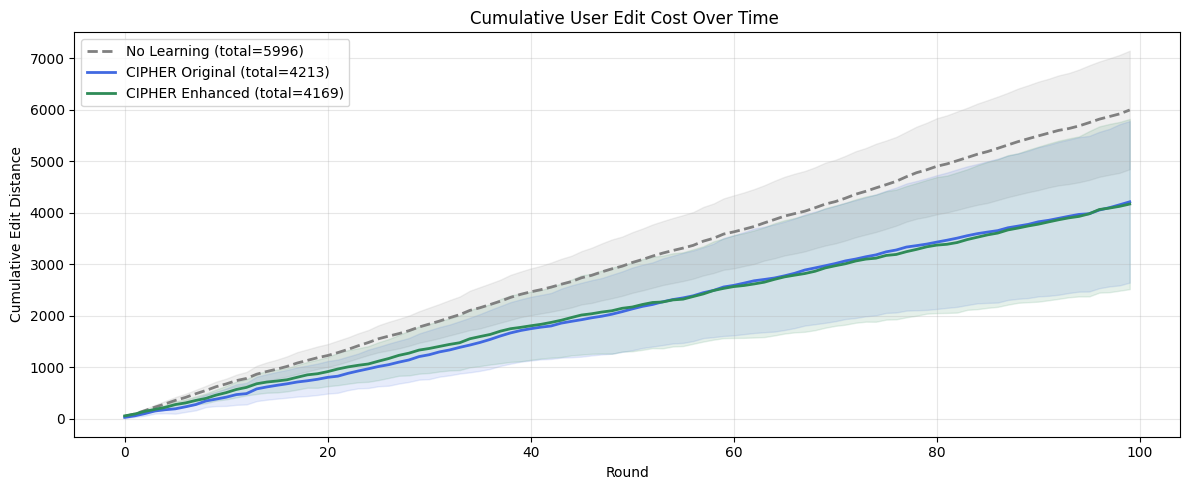

Plot 1 saved.


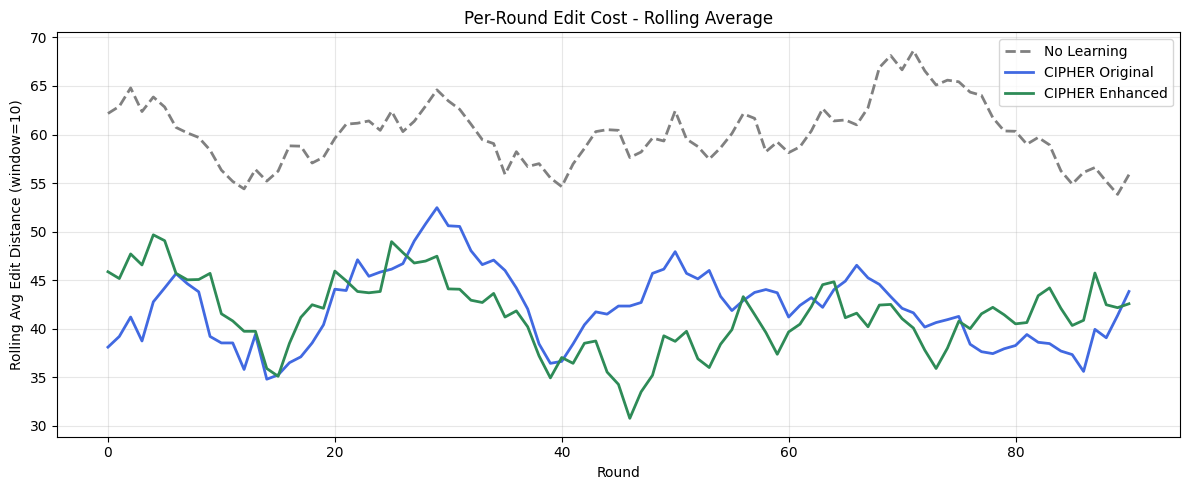

Plot 2 saved.


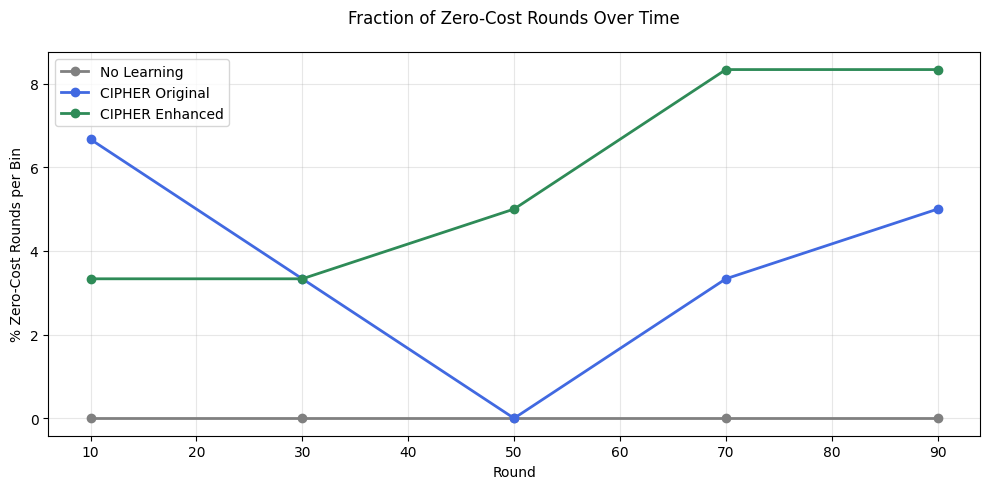

Plot 3 saved.


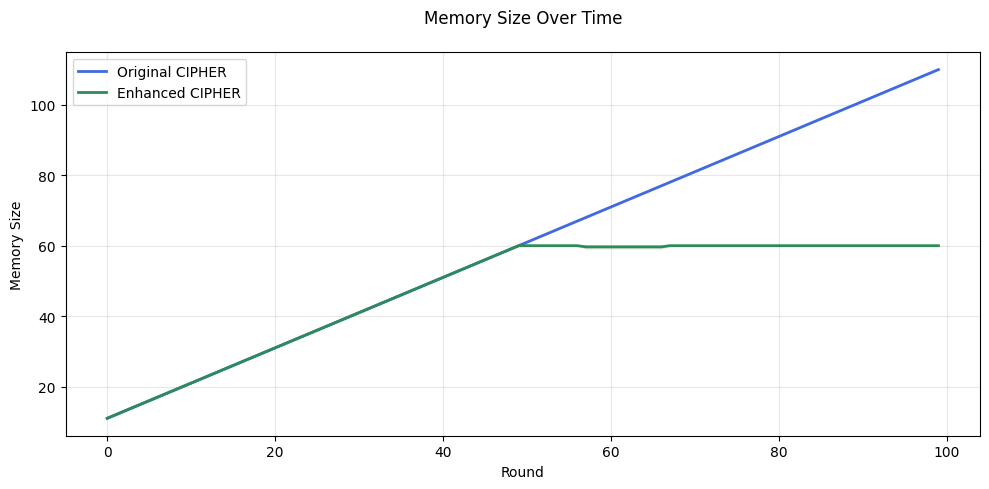

Plot 4 saved.

All plots saved to /content/drive/MyDrive/Agentic AI/cipher_results_v2
Done!


In [ ]:
import subprocess
subprocess.run([
    "pip", "install", "datasets", "sentence-transformers",
    "groq", "tiktoken", "numpy", "scikit-learn", "matplotlib", "-q"
])

# IMPORTS
import torch
import os, random, math, json, time, threading
import numpy as np
import matplotlib.pyplot as plt
import tiktoken
from concurrent.futures import ThreadPoolExecutor, as_completed
from datasets import load_dataset
from sentence_transformers import SentenceTransformer
from groq import Groq

print("CUDA available:", torch.cuda.is_available())
device = 'cuda' if torch.cuda.is_available() else 'cpu'
print(f"Using device: {device}")

GROQ_API_KEYS = [
    "key1",   
    "key2",   
    "key3",   
]

_clients   = [Groq(api_key=k) for k in GROQ_API_KEYS]
_key_index = 0
_key_lock  = threading.Lock()

def get_client():
    #round-robin order
    global _key_index
    with _key_lock:
        client = _clients[_key_index % len(_clients)]
        _key_index += 1
    return client


# CONFIG
os.environ["HF_DATASETS_CACHE"] = "/content/drive/MyDrive/Agentic AI/hf_cache"
SAVE_DIR = "/content/drive/MyDrive/Agentic AI/cipher_results_v2"
os.makedirs(SAVE_DIR, exist_ok=True)
os.makedirs("/content/drive/MyDrive/Agentic AI/hf_cache", exist_ok=True)

# EXPERIMENT SETTINGS
LATENT_PREFERENCES = {
    "news":         "bullet points only, maximum 4 bullets, each bullet under 10 words",
    "movie_review": "exactly 3 questions and answers, each answer under 15 words"
}

SEEDS = [42, 123, 456]
N_PER_SOURCE = 60
N_WARMUP_PER_SOURCE = 5
N_MAIN_PER_SOURCE = 50
K = 3
DELTA = 5
DECAY_LAMBDA = 0.05
SIM_THRESHOLD = 0.80


# LOAD DATASETS
def load_sources(n_per_source=60, seed=42):
    random.seed(seed)
    sources = {}
    cnn = load_dataset("abisee/cnn_dailymail", "3.0.0", split="test[:600]")
    imdb = load_dataset("stanfordnlp/imdb", split="test[:600]")
    sources["news"] = [
        x["article"][:1200]
        for x in random.sample(list(cnn), n_per_source)
    ]
    sources["movie_review"] = [
        x["text"][:1200]
        for x in random.sample(list(imdb), n_per_source)
    ]
    for name, docs in sources.items():
        print(f"  {name}: {len(docs)} documents loaded")
    return sources

def call_llm(prompt, max_tokens=200):
    #Call LLaMA 3.1 8B with thread-safe key rotation
    if len(prompt) > 2500:
        prompt = prompt[:2500]

    for attempt in range(5):
        client = get_client()
        try:
            response = client.chat.completions.create(
                model="llama-3.1-8b-instant",
                messages=[{"role": "user", "content": prompt}],
                max_tokens=max_tokens,
                temperature=0.3
            )
            time.sleep(0.8)
            return response.choices[0].message.content.strip()

        except Exception as e:
            err = str(e).lower()
            if "rate" in err or "429" in err:
                wait = (attempt + 1) * 20
                print(f"  Rate limit, waiting {wait}s → switching key... "
                      f"(attempt {attempt+1}/5)")
                time.sleep(wait)
            elif "400" in err or "bad request" in err:
                print("  Bad request, skipping.")
                return ""
            else:
                print(f"  LLM error: {e}")
                time.sleep(5)
    return ""


# Edit Distance 
enc = tiktoken.get_encoding("cl100k_base")

def tokenize(text):
    return enc.encode(text)

def levenshtein_distance(s1, s2):
    m, n = len(s1), len(s2)
    dp = [[0] * (n + 1) for _ in range(m + 1)]
    for i in range(m + 1): dp[i][0] = i
    for j in range(n + 1): dp[0][j] = j
    for i in range(1, m + 1):
        for j in range(1, n + 1):
            dp[i][j] = (dp[i-1][j-1] if s1[i-1] == s2[j-1]
                        else 1 + min(dp[i-1][j], dp[i][j-1], dp[i-1][j-1]))
    return dp[m][n]

def edit_cost(response, user_edit):
    return levenshtein_distance(tokenize(response), tokenize(user_edit))


# Embeddings 
print("Loading MPNET embedding model...")
embedder = SentenceTransformer('sentence-transformers/all-mpnet-base-v2',
                                   device=device)
_embed_lock = threading.Lock()

def get_embedding(text):
    with _embed_lock:
        return embedder.encode(text[:512], normalize_embeddings=True)

def cosine_similarity(v1, v2):
    return float(np.dot(v1, v2))

# TWO-STAGE SIMULATED USER
def simulated_user_edit(agent_response, latent_preference):
    # Stage 1: satisfaction check
    verdict = call_llm(
        f"Response: {agent_response[:300]}\n\n"
        f"Does this response STRICTLY follow this format: "
        f"'{latent_preference}'?\n"
        f"Answer ONLY with the single word 'yes' or 'no'.",
        max_tokens=5
    ).lower().strip()

    if verdict.startswith('yes'):
        return agent_response

    # Stage 2: rewrite
    result = call_llm(
        f"Text: {agent_response[:400]}\n"
        f"Rewrite the above text to STRICTLY follow this format: "
        f"'{latent_preference}'.\n"
        f"Do not add any explanation. Return ONLY the reformatted text.",
        max_tokens=150
    )
    return result if result else agent_response


def generate_response(article, preference=""):
    if preference:
        prompt = (f"Article: {article[:400]}\n"
                  f"Write a summary. You MUST use this exact format: "
                  f"'{preference}'.\nReturn only the summary.")
    else:
        prompt = f"Article: {article[:400]}\nWrite a short paragraph summary."
    result = call_llm(prompt, max_tokens=150)
    return result if result else "No summary generated."


def infer_preference_from_edits(agent_output, user_edit):
    result = call_llm(
        f"Original text: {agent_output[:200]}\n"
        f"User reformatted it to: {user_edit[:200]}\n"
        f"Describe the user's formatting preference in under 10 words.\n"
        f"Answer only with the preference description:",
        max_tokens=20
    )
    return result if result else ""


#Original CIPHER: LLM merges k preferences into one
def aggregate_preferences_llm(preferences):
    if len(preferences) == 1:
        return preferences[0]
    pref_list = "\n".join(f"- {p}" for p in preferences)
    result = call_llm(
        f"List of user preferences from similar past contexts:\n{pref_list}\n"
        f"Summarize these into ONE short phrase (under 10 words) representing "
        f"the user's formatting preference:",
        max_tokens=20
    )
    return result if result else preferences[0]

# NO LEARNING BASELINE
def run_no_learning(all_contexts, n_warmup, label=""):
    tag = f"[No Learning{' | ' + label if label else ''}]"
    print(f"\n{tag} Starting...")
    all_costs, zero_flags = [], []

    for t, (article, source) in enumerate(all_contexts):
        latent_pref = LATENT_PREFERENCES[source]
        yt= generate_response(article)
        yt_prime= simulated_user_edit(yt, latent_pref)
        cost= edit_cost(yt, yt_prime)
        all_costs.append(cost)
        zero_flags.append(1 if cost == 0 else 0)
        if t % 20 == 0:
            phase = "W" if t < n_warmup else "M"
            print(f"  {tag} [{phase}] t={t+1} cost={cost}")

    main_costs = all_costs[n_warmup:]
    main_zeros = zero_flags[n_warmup:]
    print(f"  {tag} Done. Total={sum(main_costs)}")
    return main_costs, sum(main_costs), main_zeros

#ORIGINAL CIPHER
def run_cipher_original(all_contexts, n_warmup, k=K, delta=DELTA, label=""):
    tag = f"[CIPHER Original{' | ' + label if label else ''}]"
    print(f"\n{tag} Starting (k={k})...")
    history = []
    all_costs, zero_flags, memory_sizes = [], [], []

    for t, (article, source) in enumerate(all_contexts):
        latent_pref = LATENT_PREFERENCES[source]
        article_emb = get_embedding(article)

        if history:
            sims = sorted(
                [(cosine_similarity(article_emb, h["emb"]), h["pref"])
                 for h in history], reverse=True)
            ft = aggregate_preferences_llm([p for _, p in sims[:k]])
        else:
            ft = ""

        yt = generate_response(article, ft)
        yt_prime = simulated_user_edit(yt, latent_pref)
        cost = edit_cost(yt, yt_prime)
        all_costs.append(cost)
        zero_flags.append(1 if cost == 0 else 0)

        if cost > delta:
            ft_new = infer_preference_from_edits(yt, yt_prime)
            if ft_new:
                history.append({"emb": article_emb, "pref": ft_new, "t": t})
        elif ft:
            history.append({"emb": article_emb, "pref": ft, "t": t})

        if t >= n_warmup:
            memory_sizes.append(len(history))

        if t % 20 == 0:
            phase = "W" if t < n_warmup else "M"
            mark  = "✓" if cost == 0 else str(cost)
            print(f"  {tag} [{phase}] t={t+1} cost={mark} hist={len(history)}")

    main_costs = all_costs[n_warmup:]
    main_zeros = zero_flags[n_warmup:]
    print(f"  {tag} Done. Total={sum(main_costs)}")
    return main_costs, sum(main_costs), main_zeros, memory_sizes

# ENHANCED CIPHER
def aggregate_preferences_weighted(retrieved_items, query_emb, current_t,
                                    decay_lambda=DECAY_LAMBDA):
    if len(retrieved_items) == 1:
        return retrieved_items[0]["pref"]
    best_w, best_p = -1, retrieved_items[0]["pref"]
    for item in retrieved_items:
        w = (cosine_similarity(query_emb, item["emb"])
             * math.exp(-decay_lambda * (current_t - item["t"])))
        if w > best_w:
            best_w, best_p = w, item["pref"]
    return best_p


def update_preference_with_decay(history, new_emb, new_pref, current_t,
                                  decay_lambda=DECAY_LAMBDA,
                                  sim_threshold=SIM_THRESHOLD):
    merged = False
    for item in history:
        if cosine_similarity(new_emb, item["emb"]) > sim_threshold:
            combined     = item["emb"] + new_emb
            item["emb"]  = combined / np.linalg.norm(combined)
            item["pref"] = new_pref
            item["t"]    = current_t
            merged = True
            break
    if not merged:
        history.append({"emb": new_emb, "pref": new_pref, "t": current_t})
    history[:] = [h for h in history
                  if math.exp(-decay_lambda * (current_t - h["t"])) > 0.05]
    return history


def run_cipher_enhanced(all_contexts, n_warmup,
                         k=K, delta=DELTA,
                         decay_lambda=DECAY_LAMBDA,
                         sim_threshold=SIM_THRESHOLD,
                         label=""):
    tag = f"[CIPHER Enhanced{' | ' + label if label else ''}]"
    print(f"\n{tag} Starting (k={k}, λ={decay_lambda})...")
    history = []
    all_costs, zero_flags, memory_sizes = [], [], []

    for t, (article, source) in enumerate(all_contexts):
        latent_pref = LATENT_PREFERENCES[source]
        article_emb = get_embedding(article)

        if history:
            sims = sorted(
                [(cosine_similarity(article_emb, h["emb"]), h)
                 for h in history], reverse=True)
            ft = aggregate_preferences_weighted(
                [h for _, h in sims[:k]], article_emb, t, decay_lambda)
        else:
            ft = ""

        yt = generate_response(article, ft)
        yt_prime = simulated_user_edit(yt, latent_pref)
        cost = edit_cost(yt, yt_prime)
        all_costs.append(cost)
        zero_flags.append(1 if cost == 0 else 0)

        if cost > delta:
            ft_new = infer_preference_from_edits(yt, yt_prime)
            if ft_new:
                history = update_preference_with_decay(
                    history, article_emb, ft_new, t, decay_lambda, sim_threshold)
        elif ft:
            history = update_preference_with_decay(
                history, article_emb, ft, t, decay_lambda, sim_threshold)

        if t >= n_warmup:
            memory_sizes.append(len(history))

        if t % 20 == 0:
            phase = "W" if t < n_warmup else "M"
            mark  = "✓" if cost == 0 else str(cost)
            print(f"  {tag} [{phase}] t={t+1} cost={mark} mem={len(history)}")

    main_costs = all_costs[n_warmup:]
    main_zeros = zero_flags[n_warmup:]
    print(f"  {tag} Done. Total={sum(main_costs)}")
    return main_costs, sum(main_costs), main_zeros, memory_sizes

# PREPARE CONTEXTS
def prepare_all_contexts(sources, seed,
                          n_warmup_per_source=N_WARMUP_PER_SOURCE,
                          n_main_per_source=N_MAIN_PER_SOURCE):
    random.seed(seed)
    names  = list(sources.keys())
    warmup = [(sources[n][n_main_per_source + i], n)
              for i in range(n_warmup_per_source) for n in names]
    main = [(doc, n) for n in names for doc in sources[n][:n_main_per_source]]
    random.shuffle(main)
    return warmup + main, len(warmup)

# PARALLEL SEED RUNNER
def save_seed(seed, nl, orig, enh):
    path = f"{SAVE_DIR}/seed_{seed}.json"
    with open(path, "w") as f:
        json.dump({
            "no_learning":     {"costs": nl[0],   "zeros": nl[2]},
            "cipher_original": {"costs": orig[0], "zeros": orig[2],
                                 "memory": orig[3]},
            "cipher_enhanced": {"costs": enh[0],  "zeros": enh[2],
                                 "memory": enh[3]},
        }, f)
    print(f"  Saved seed {seed} → {path}")

# Run No Learning, Original CIPHER, and Enhanced CIPHER for one seed in three simultaneous threads
def run_seed_parallel(seed):
    print(f"\n{'='*65}\n  SEED {seed} — running 3 methods in parallel\n{'='*65}")

    sources = load_sources(n_per_source=N_PER_SOURCE, seed=seed)
    all_contexts, n_warmup = prepare_all_contexts(sources, seed=seed)
    n_main = len(all_contexts) - n_warmup
    print(f"Warmup: {n_warmup} | Main: {n_main} | Total: {len(all_contexts)}")

    lbl = f"seed={seed}"

    # Map task names to callables
    tasks = {
        "no_learning": lambda: run_no_learning(
            all_contexts, n_warmup, label=lbl),
        "cipher_original": lambda: run_cipher_original(
            all_contexts, n_warmup, label=lbl),
        "cipher_enhanced": lambda: run_cipher_enhanced(
            all_contexts, n_warmup, label=lbl),
    }

    results = {}
    with ThreadPoolExecutor(max_workers=3) as executor:
        future_to_name = {executor.submit(fn): name
                          for name, fn in tasks.items()}
        for future in as_completed(future_to_name):
            name = future_to_name[future]
            try:
                results[name] = future.result()
                print(f"  ✓ {name} completed for seed {seed}")
            except Exception as exc:
                print(f"  ✗ {name} raised an exception for seed {seed}: {exc}")
                raise

    nl = results["no_learning"]
    orig = results["cipher_original"]
    enh = results["cipher_enhanced"]

    # Save immediately
    save_seed(seed, nl, orig, enh)

    # Per-seed summary
    nl_total = nl[1]
    print(f"\nSeed {seed} summary:")
    for name, res in [("No Learning", nl), ("CIPHER Original", orig),
                      ("CIPHER Enhanced", enh)]:
        total  = res[1]
        zeros  = res[2]
        red = (1 - total / nl_total) * 100
        zp = sum(zeros) / len(zeros) * 100
        print(f"  {name:<25} total={total}  reduction={red:.1f}%  "
              f"zero-cost={zp:.1f}%")

    return nl, orig, enh


# LOAD SAVED SEED
def load_seed(seed):
    path = f"{SAVE_DIR}/seed_{seed}.json"
    with open(path) as f:
        d = json.load(f)
    nl   = (d["no_learning"]["costs"],
            sum(d["no_learning"]["costs"]),
            d["no_learning"]["zeros"])
    orig = (d["cipher_original"]["costs"],
            sum(d["cipher_original"]["costs"]),
            d["cipher_original"]["zeros"],
            d["cipher_original"]["memory"])
    enh  = (d["cipher_enhanced"]["costs"],
            sum(d["cipher_enhanced"]["costs"]),
            d["cipher_enhanced"]["zeros"],
            d["cipher_enhanced"]["memory"])
    print(f"  Loaded seed {seed} from {path}")
    return nl, orig, enh


#MAIN LOOP
print("\n" + "="*65)
print("  STARTING...")
print("="*65)

all_results = {
    "no_learning":     {"costs": [], "zeros": []},
    "cipher_original": {"costs": [], "zeros": [], "memory": []},
    "cipher_enhanced": {"costs": [], "zeros": [], "memory": []},
}

for seed in SEEDS:
    cached = f"{SAVE_DIR}/seed_{seed}.json"
    if os.path.exists(cached):
        print(f"\nFound saved results for seed {seed}, loading from Drive...")
        nl, orig, enh = load_seed(seed)
    else:
        nl, orig, enh = run_seed_parallel(seed)

    all_results["no_learning"]["costs"].append(nl[0])
    all_results["no_learning"]["zeros"].append(nl[2])
    all_results["cipher_original"]["costs"].append(orig[0])
    all_results["cipher_original"]["zeros"].append(orig[2])
    all_results["cipher_original"]["memory"].append(orig[3])
    all_results["cipher_enhanced"]["costs"].append(enh[0])
    all_results["cipher_enhanced"]["zeros"].append(enh[2])
    all_results["cipher_enhanced"]["memory"].append(enh[3])

# Save combined
save_data = {}
for method, data in all_results.items():
    save_data[method] = {k: [list(a) for a in v] for k, v in data.items()}
with open(f"{SAVE_DIR}/results_all_seeds.json", "w") as f:
    json.dump(save_data, f)
print(f"\nAll results saved to {SAVE_DIR}/results_all_seeds.json")

#SUMMARY TABLE

def compute_stats(costs_list):
    totals = [sum(c) for c in costs_list]
    return np.mean(totals), np.std(totals)

def zero_pct(zeros_list):
    return np.mean([sum(z) / len(z) * 100 for z in zeros_list])

nl_mean,   nl_std   = compute_stats(all_results["no_learning"]["costs"])
orig_mean, orig_std = compute_stats(all_results["cipher_original"]["costs"])
enh_mean,  enh_std  = compute_stats(all_results["cipher_enhanced"]["costs"])
n_main_rounds = N_MAIN_PER_SOURCE * len(LATENT_PREFERENCES)

print("\n" + "="*80)
print("FINAL RESULTS  (mean ± std across 3 seeds)")
print("="*80)
print(f"{'Method':<25} {'Total Cost':>18} {'Avg/Round':>12} "
      f"{'Reduction':>12} {'Zero-cost%':>12}")
print("-"*80)
for name, mean, std, zp in [
    ("No Learning",     nl_mean,   nl_std,
     zero_pct(all_results["no_learning"]["zeros"])),
    ("CIPHER Original", orig_mean, orig_std,
     zero_pct(all_results["cipher_original"]["zeros"])),
    ("CIPHER Enhanced", enh_mean,  enh_std,
     zero_pct(all_results["cipher_enhanced"]["zeros"])),
]:
    avg = mean / n_main_rounds
    red = (1 - mean / nl_mean) * 100
    print(f"{name:<25} {mean:>8.0f} ± {std:<6.0f} {avg:>12.1f} "
          f"{red:>11.1f}% {zp:>11.1f}%")

# PLOTS

def mean_across_seeds(data_list):
    n = min(len(d) for d in data_list)
    arr = np.array([d[:n] for d in data_list])
    return arr.mean(0), arr.std(0)

nl_mc, nl_sc = mean_across_seeds(all_results["no_learning"]["costs"])
orig_mc, orig_sc = mean_across_seeds(all_results["cipher_original"]["costs"])
enh_mc, enh_sc  = mean_across_seeds(all_results["cipher_enhanced"]["costs"])
rounds = np.arange(len(nl_mc))

PALETTE = [
    ("No Learning", "no_learning", "gray","--"),
    ("CIPHER Original", "cipher_original", "royalblue", "-"),
    ("CIPHER Enhanced", "cipher_enhanced", "seagreen",  "-"),
]

# --- Plot 1: Cumulative cost ---
fig, ax = plt.subplots(figsize=(12, 5))
for label, _, color, ls, mc, sc in zip(
        [p[0] for p in PALETTE], [p[1] for p in PALETTE],
        [p[2] for p in PALETTE], [p[3] for p in PALETTE],
        [nl_mc, orig_mc, enh_mc], [nl_sc, orig_sc, enh_sc]):
    cm = np.cumsum(mc)
    cs = np.cumsum(sc)
    ax.plot(rounds, cm, label=f"{label} (total={cm[-1]:.0f})",
            color=color, linestyle=ls, linewidth=2)
    ax.fill_between(rounds, cm - cs, cm + cs, alpha=0.12, color=color)
ax.set(xlabel="Round", ylabel="Cumulative Edit Distance",
       title="Cumulative User Edit Cost Over Time ")
ax.legend()
ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot1_cumulative.png", dpi=150)
plt.show()
print("Plot 1 saved.")

# --- Plot 2: Rolling average ---
W = 10
def roll(a): return np.convolve(a, np.ones(W) / W, mode='valid')

fig, ax = plt.subplots(figsize=(12, 5))
for label, _, color, ls, mc in zip(
        [p[0] for p in PALETTE], [p[1] for p in PALETTE],
        [p[2] for p in PALETTE], [p[3] for p in PALETTE],
        [nl_mc, orig_mc, enh_mc]):
    ax.plot(roll(mc), label=label, color=color, linestyle=ls, linewidth=2)
ax.set(xlabel="Round", ylabel=f"Rolling Avg Edit Distance (window={W})",
       title="Per-Round Edit Cost - Rolling Average")
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot2_rolling.png", dpi=150)
plt.show()
print("Plot 2 saved.")

# --- Plot 3: Zero-cost fraction (binned) ---
BIN = 20
n_bins = len(nl_mc) // BIN

fig, ax = plt.subplots(figsize=(10, 5))
for label, key, color, _ in PALETTE:
    vals = []
    for b in range(n_bins):
        s, e = b * BIN, (b + 1) * BIN
        vals.append(np.mean([
            np.mean(z[s:e]) * 100
            for z in all_results[key]["zeros"]
        ]))
    ax.plot([(b + 0.5) * BIN for b in range(n_bins)], vals,
            marker='o', label=label, color=color, linewidth=2)
ax.set(xlabel="Round", ylabel="% Zero-Cost Rounds per Bin",
       title="Fraction of Zero-Cost Rounds Over Time\n") # (Higher = agent correctly predicted user preference -> no edits needed)
ax.legend(); ax.grid(alpha=0.3)
plt.tight_layout()
plt.savefig(f"{SAVE_DIR}/plot3_zero_cost.png", dpi=150)
plt.show()
print("Plot 3 saved.")

# --- Plot 4: Memory size ---
if (all_results["cipher_original"]["memory"] and
        all_results["cipher_enhanced"]["memory"]):
    orig_mm, orig_ms = mean_across_seeds(
        all_results["cipher_original"]["memory"])
    enh_mm,  enh_ms  = mean_across_seeds(
        all_results["cipher_enhanced"]["memory"])
    mr = np.arange(len(orig_mm))

    fig, ax = plt.subplots(figsize=(10, 5))
    ax.plot(mr, orig_mm, label="Original CIPHER",
            color="royalblue", linewidth=2)
    ax.fill_between(mr, orig_mm - orig_ms, orig_mm + orig_ms,
                    alpha=0.12, color="royalblue")
    ax.plot(mr, enh_mm, label="Enhanced CIPHER",
            color="seagreen", linewidth=2)
    ax.fill_between(mr, enh_mm - enh_ms, enh_mm + enh_ms,
                    alpha=0.12, color="seagreen")
    ax.set(xlabel="Round",
           ylabel="Memory Size",
           title="Memory Size Over Time\n")
    ax.legend(); ax.grid(alpha=0.3)
    plt.tight_layout()
    plt.savefig(f"{SAVE_DIR}/plot4_memory.png", dpi=150)
    plt.show()
    print("Plot 4 saved.")

print(f"\nAll plots saved to {SAVE_DIR}")
print("Done!")